# Week 2 — Linear regression with Lasso, Ridge and Elastic Net regularization
**Kumar Gaurav · DX799 O1 Data Science Capstone · Milestone One notebook appendix**

For Week 2, include concepts such as linear regression with lasso, ridge, and elastic net regression.

**Question:** when we give linear regression many features (all squares and pairwise interactions), does **regularization**
(shrinking coefficients) give better out-of-sample predictions than plain OLS, and which features survive?
Targets (same as Week 1): Lending Club `int_rate` and Taiwan `log(LIMIT_BAL)`.

## Part A — Data quality evaluation (done before any modeling)
Before fitting any model we check the data the way a careful analyst would by hand: what is in the file, what is missing,
what is duplicated, which values are impossible, which columns would leak the answer, and what the target looks like.
Every issue found is written into a **data-quality summary table** (issue, rows affected, action) so a reader can judge
how much the cleaning could have influenced the results. The same block appears in every weekly notebook so each one runs on its own.

**Datasets (one framing: consumer credit default risk)**
* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005, target = default in October 2005.

## Cell 1 — Imports and loading the Lending Club audit columns
### Why are we doing this?
Everything later depends on the raw data being read correctly. We load only the ~28 columns we will audit or model instead
of all 145, because the full file is ~2.26M rows and loading everything wastes memory.
### What are we doing?
* `pandas` (`pd`) holds tables, `numpy` (`np`) does math, `matplotlib`/`seaborn` draw charts, `kagglehub` downloads/caches the Kaggle dataset.
* `pd.read_csv(..., usecols=LC_COLS)` reads only the listed columns. Four *post-outcome* columns (`total_pymnt`, `recoveries`, `last_pymnt_amnt`, `out_prncp`) are loaded **only** so we can prove later that they leak the answer and must be removed.
* `SEED = 42` fixes all random sampling so the notebook is reproducible (the seed makes results repeatable, not "correct").
### Alternatives
Reading all columns (simpler but ~5× the memory) or using a database/parquet copy (faster for repeated runs).
### What should we examine after execution?
The shape (rows × columns), the mix of data types (numbers vs text), and whether the first rows look sensible.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns we audit/model (the raw file is 2.26M x 145)
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           # post-outcome columns, loaded ONLY to demonstrate the leakage screen
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)
print(f"Lending Club raw shape (audited columns): {lc_raw.shape}")
print(lc_raw.dtypes.value_counts().to_string())
display(lc_raw.head(3))

Lending Club raw shape (audited columns): (2260668, 28)
float64    16
str         9
int64       3


,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_util,total_acc,out_prncp,total_pymnt,recoveries,last_pymnt_amnt,policy_code,application_type,mort_acc,pub_rec_bankruptcies
0,NaN,2500,36 months,13.56,C,C1,10+ years,RENT,55000.0,Not Verified,...,10.3,34.0,2386.02,167.02,0.0,84.92,1,Individual,0.0,1.0
1,NaN,30000,60 months,18.94,D,D2,10+ years,MORTGAGE,90000.0,Source Verified,...,24.2,44.0,29387.75,1507.11,0.0,777.23,1,Individual,3.0,1.0
2,NaN,5000,36 months,17.97,D,D1,6 years,MORTGAGE,59280.0,Source Verified,...,19.1,13.0,4787.21,353.89,0.0,180.69,1,Individual,2.0,0.0


## Result Interpretation — Lending Club load
### What did we actually get?
**2,260,668 rows × 28 audited columns**: 16 float, 9 text (`str`), 3 integer columns. In the first three rows, `id` shows `NaN`, the numbers look plausible (loan amounts 2,500–30,000; rates 13.56–18.94%), and `term` has a leading space (`" 36 months"`).
### What does it mean?
The file loaded correctly. Two things need attention right away: the identifier is empty, and text columns need parsing (`term`). These first rows are *current* loans, which is why `out_prncp` (outstanding principal) is non-zero. That previews the censoring problem handled two cells below.
### What should we do next?
Audit missingness across all 145 columns before choosing which ones to trust.

## Cell 2 — Null-column audit across the full 145-column file
### Why are we doing this?
Missing data silently shrinks or biases a sample. Columns that are mostly empty cannot be used, and columns that are
100% empty are useless (including identifiers we might have wanted for duplicate checks).
### How does it work?
The file is read in chunks of 500,000 rows; for each chunk `isnull().sum()` counts missing cells per column, and the counts
are added up. Dividing by the total rows gives the **missing %** per column. Chunking keeps memory low.
### Key concept — missingness
**Missing completely at random** (safe to drop) vs **missing not at random** (dropping can bias results, e.g. income missing
more often for riskier borrowers). With very small missing % the choice barely matters; with large % it matters a lot.
### What should we examine after execution?
How many columns are fully empty, how many exceed 50% missing, and the missing % of the columns we actually model.

In [2]:
# Null audit on the FULL 145-column header (chunked so memory stays small)
null_cnt, n_rows = None, 0
for ch in pd.read_csv(LC_PATH, chunksize=500_000, low_memory=False):
    c = ch.isnull().sum(); null_cnt = c if null_cnt is None else null_cnt + c; n_rows += len(ch)
null_pct = (null_cnt / n_rows * 100).sort_values(ascending=False)
print(f"All columns: {len(null_pct)} | rows: {n_rows:,}")
print(f"Columns 100% empty: {(null_pct == 100).sum()} -> {null_pct[null_pct == 100].index.tolist()}")
print(f"Columns > 50% missing (dropped from consideration): {(null_pct > 50).sum()}")
print("\nMissing % for the columns we use:")
use_pct = null_pct.reindex([c for c in LC_COLS if c != "id"]).round(3)
print(use_pct[use_pct > 0].to_string())

All columns: 145 | rows: 2,260,668
Columns 100% empty: 3 -> ['id', 'url', 'member_id']
Columns > 50% missing (dropped from consideration): 44

Missing % for the columns we use:
emp_length              6.498
dti                     0.076
delinq_2yrs             0.001
inq_last_6mths          0.001
open_acc                0.001
pub_rec                 0.001
revol_util              0.080
total_acc               0.001
mort_acc                2.213
pub_rec_bankruptcies    0.060


## Result Interpretation — Null-column audit
### What did we actually get?
* **3 of 145 columns are 100% empty:** `id`, `url`, `member_id`.
* **44 columns are more than 50% missing.** These are mostly hardship/settlement and joint-applicant fields that only exist for some loans. None of them are used.
* Among the columns we use, missingness is small: `emp_length` 6.50%, `mort_acc` 2.21%, `revol_util` 0.080%, `dti` 0.076%, `pub_rec_bankruptcies` 0.060%, and the rest 0.001%.
### What does it mean?
* Missingness in our model columns is low enough that dropping incomplete rows loses only a few percent. Most of that comes from `mort_acc`.
* `emp_length` (6.5% missing) is excluded from the models because its missingness may not be random. Borrowers who leave it blank may differ in risk.
* The empty `id` means duplicates must be detected by comparing whole rows.
### What can we NOT conclude?
That the dropped rows are like the kept rows. With about 2% of rows dropped, any bias is likely small, but it is not tested.

## Cell 3 — Closed loans, duplicates, invalid ranges, constants, cardinality and leakage
### Why are we doing this?
A model learns whatever is in the data — including errors. This cell applies explicit, documented decisions:
* **Outcome definition:** only closed loans (`Fully Paid`, `Charged Off`, `Default`) have a known outcome. `Current`/`Late` loans are censored, so including them would mislabel future defaults as "repaid".
* **Duplicates:** `id` is empty in this Kaggle copy, so we check exact duplicate rows instead.
* **Impossible values:** `dti` (debt-to-income) below 0 or the sentinel 999; income of 0 (cannot take a log or ratio).
* **Extreme but possible values:** `revol_util` above 100% means the borrower is over their credit limit — real, so we clip rather than drop.
* **Rare categories:** `home_ownership` ANY/NONE are merged into OTHER so one-hot encoding does not create near-empty columns.
* **Constant columns** carry no information.
* **Leakage screen:** a column known only *after* the outcome (e.g., total payments received, recoveries) would make the model look brilliant on paper and useless in practice. We print its mean by outcome to show the leak, then drop it.
### Alternatives
Imputing missing values (median or model-based) instead of dropping; winsorizing at percentiles instead of fixed caps.
With <1% of rows affected, listwise dropping is simpler and easier to defend.
### What should we examine after execution?
How many loans are closed, how many rows each check affects, and how strongly the leakage columns separate the outcomes.

In [3]:
# Keep closed loans only (outcome known); 'Current'/'Late' loans are censored
CLOSED = ["Fully Paid", "Charged Off", "Default"]
print("loan_status counts:"); print(lc_raw["loan_status"].value_counts().to_string())
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].copy()
print(f"\nClosed loans: {len(lc):,}")

dq = []  # (issue, rows affected, action)
dq.append(("Open/censored loan_status", len(lc_raw) - len(lc), "dropped (outcome unknown)"))
dq.append(("id column 100% null", 0, "cannot dedupe on id; deduped on full row instead"))
dups = lc.drop(columns=["id"]).duplicated().sum(); dq.append(("Exact duplicate rows", dups, "dropped"))
lc = lc.drop(columns=["id"]).drop_duplicates()

# Invalid / impossible ranges
bad_dti = ((lc["dti"] < 0) | (lc["dti"] > 100)).sum()
dq.append(("dti < 0 or > 100% (sentinel 999 / data error)", bad_dti, "set to NaN then dropped"))
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
hi_util = (lc["revol_util"] > 100).sum()
dq.append(("revol_util > 100%", hi_util, "clipped to 150 (over-limit is real but extreme)"))
lc["revol_util"] = lc["revol_util"].clip(upper=150)
zero_inc = (lc["annual_inc"] <= 0).sum()
dq.append(("annual_inc <= 0", zero_inc, "dropped (cannot log/ratio)"))
lc = lc[lc["annual_inc"] > 0]
hi_inc = (lc["annual_inc"] > 1e6).sum()
dq.append(("annual_inc > $1M", hi_inc, "kept; modeled as log1p(annual_inc)"))
odd_home = lc["home_ownership"].isin(["ANY", "NONE", "OTHER"]).sum()
dq.append(("home_ownership ANY/NONE/OTHER", odd_home, "merged into OTHER"))
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Constant / near-constant and cardinality
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
print("Constant columns:", const)
dq.append(("Constant columns " + str(const), 0, "column dropped (no information)"))
lc = lc.drop(columns=const)
cat_cols = lc.select_dtypes("object").columns
print("Categorical cardinality:", lc[cat_cols].nunique().to_dict())

# Leakage screen: columns only known AFTER the outcome
LEAK = ["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
print("\nLeakage check: mean of post-outcome columns by outcome")
print(lc.groupby(lc["loan_status"] != "Fully Paid")[LEAK].mean().round(1).rename(index={False: "repaid", True: "default"}).to_string())
dq.append(("Post-outcome columns " + ", ".join(LEAK), 0, "columns dropped (target leakage)"))
lc = lc.drop(columns=LEAK)

lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
before = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies", "inq_last_6mths", "open_acc", "total_acc"])
dq.append(("Remaining NaNs in model columns", before - len(lc), "dropped (listwise)"))
lc["log_annual_inc"] = np.log1p(lc["annual_inc"]); lc["log_revol_bal"] = np.log1p(lc["revol_bal"])
lc["term_months"] = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"\nClean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

loan_status counts:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31

Closed loans: 1,303,638


Constant columns: ['policy_code']
Categorical cardinality: {'term': 2, 'grade': 7, 'sub_grade': 35, 'emp_length': 11, 'home_ownership': 4, 'verification_status': 3, 'loan_status': 3, 'purpose': 14, 'application_type': 2}

Leakage check: mean of post-outcome columns by outcome
             total_pymnt  recoveries  last_pymnt_amnt  out_prncp
loan_status                                                     
repaid           16439.4         0.0           6720.8        0.0
default           8228.0      1173.9            472.6        1.3



Clean Lending Club rows: 1,254,818 | default rate: 20.28%


## Result Interpretation — Cleaning decisions
### What did we actually get?
* **Outcomes:** 1,041,952 Fully Paid, 261,655 Charged Off and 31 Default form the **1,303,638 closed loans**. The 919,695 `Current` loans and the late or grace-period loans are excluded.
* **Constant column:** `policy_code` (always 1), dropped.
* **Cardinality:** `sub_grade` has 35 levels and `purpose` has 14. Both are manageable for one-hot encoding.
* **Leakage proof:** repaid loans average **$16,439** in `total_pymnt` and **$0** in `recoveries`. Defaulted loans average **$8,228** and **$1,174**. Recoveries are non-zero *only* after a default, so a model given this column would find the answer by reading the outcome. That is why it is dropped.
* **Final:** **1,254,818 clean closed loans**, with a **20.28%** default rate.
### What does it mean?
The outcome definition and the leakage screen matter most. Including `Current` loans would label future defaults as repaid, and including recoveries would give near-perfect but meaningless accuracy.

## Cell 4 — Lending Club data-quality summary, distributions and target balance
### Why are we doing this?
The summary table is the audit trail. The `describe()` table and histograms show skew and outliers, and the class balance
tells us which metrics are honest (with ~20% defaults, "predict everyone repays" already scores ~80% accuracy).
### What should we examine after execution?
Rows affected per issue (as a share of the total), mean vs median gaps (skew), the default share, and the skew of income before/after `log1p`.

,issue,rows_affected,action
0,Open/censored loan_status,957030,dropped (outcome unknown)
1,id column 100% null,0,cannot dedupe on id; deduped on full row instead
2,Exact duplicate rows,0,dropped
3,dti < 0 or > 100% (sentinel 999 / data error),478,set to NaN then dropped
4,revol_util > 100%,4537,clipped to 150 (over-limit is real but extreme)
5,annual_inc <= 0,302,dropped (cannot log/ratio)
6,annual_inc > $1M,279,kept; modeled as log1p(annual_inc)
7,home_ownership ANY/NONE/OTHER,459,merged into OTHER
8,Constant columns ['policy_code'],0,column dropped (no information)
9,"Post-outcome columns total_pymnt, recoveries, ...",0,columns dropped (target leakage)


,count,mean,std,min,25%,50%,75%,max
loan_amnt,1254818.0,14521.03,8716.03,1000.00,8000.00,12000.00,20000.00,40000.00
int_rate,1254818.0,13.30,4.79,5.31,9.75,12.79,16.02,30.99
annual_inc,1254818.0,76459.53,70288.00,430.00,46000.00,65000.00,90000.00,10999200.00
dti,1254818.0,18.35,8.67,0.00,11.95,17.78,24.26,100.00
revol_util,1254818.0,51.98,24.34,0.00,33.80,52.30,70.70,150.00
open_acc,1254818.0,11.68,5.48,1.00,8.00,11.00,14.00,90.00


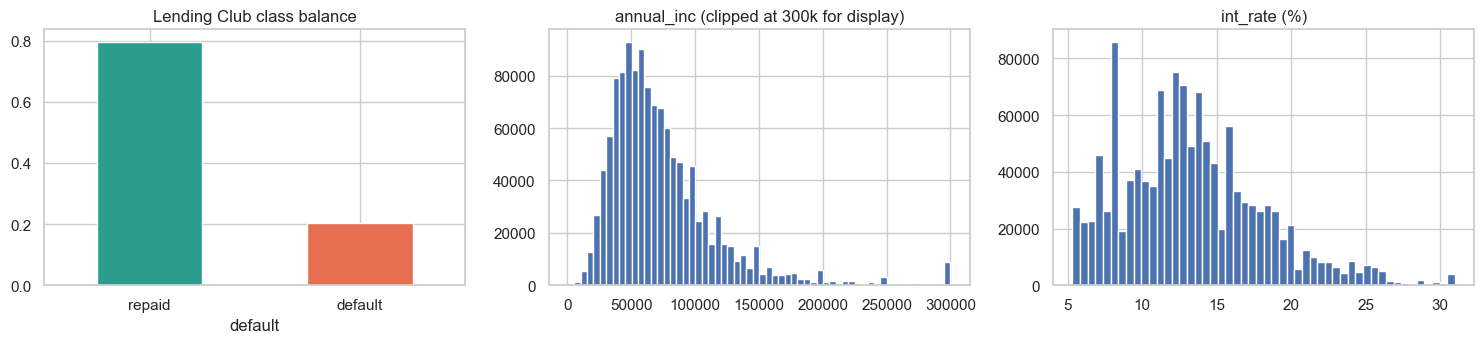

Skew annual_inc raw vs log1p: 47.64 -> 0.21


In [4]:
lc_dq = pd.DataFrame(dq, columns=["issue", "rows_affected", "action"])
display(lc_dq)
display(lc[["loan_amnt", "int_rate", "annual_inc", "dti", "revol_util", "open_acc"]].describe().round(2).T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
lc["default"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Lending Club class balance"); ax[0].set_xticklabels(["repaid", "default"], rotation=0)
ax[1].hist(lc["annual_inc"].clip(upper=300000), bins=60); ax[1].set_title("annual_inc (clipped at 300k for display)")
ax[2].hist(lc["int_rate"], bins=50); ax[2].set_title("int_rate (%)")
plt.tight_layout(); plt.show()
print("Skew annual_inc raw vs log1p:", round(lc["annual_inc"].skew(), 2), "->", round(lc["log_annual_inc"].skew(), 2))

## Result Interpretation — Lending Club data-quality summary
### What did we actually get?
| Issue | Rows affected | Share of closed loans |
|---|---|---|
| Open or censored status | 957,030 | (dropped before the closed count) |
| `dti` < 0 or > 100 | 478 | 0.04% |
| `revol_util` > 100% | 4,537 | 0.35% (clipped at 150) |
| `annual_inc` ≤ 0 | 302 | 0.02% |
| `annual_inc` > $1M | 279 | kept, log-transformed |
| home_ownership ANY/NONE/OTHER | 459 | merged |
| Remaining NaNs | 48,518 | 3.7% (mostly `mort_acc`) |

Exact duplicate rows: **0**. After cleaning: `int_rate` mean 13.30% with SD 4.79, range 5.31–30.99. `dti` now runs 0–100.
* **Skew:** `annual_inc` has mean $76,437 vs median $65,000, a max of $10,999,200, and **skew 47.63, which falls to 0.18 after `log1p`**.
* **Charts:** the class-balance chart shows about 80/20 repaid vs default.
### What does it mean?
* **Income must be logged.** Without the log, a few millionaires would dominate any linear model.
* **Accuracy is a weak metric here.** An "everyone repays" rule already scores about 80%, so later weeks judge models by ROC-AUC, F1 and recall.
* **Cleaning removed about 4% of closed loans,** mostly rows with an incomplete credit history.
### What should we do next?
Run the same audit on the Taiwan dataset.

## Cell 5 — Loading the Taiwan credit-card default data
### Why are we doing this?
This is the second dataset. It is a different market (revolving credit cards, Taiwan 2005) with the same question —
who will default — so it lets us check whether conclusions generalize beyond Lending Club.
### What are we doing?
Downloading/caching via `kagglehub` and reading the single CSV. Columns: `LIMIT_BAL` (credit limit, NT$), `SEX`, `EDUCATION`,
`MARRIAGE`, `AGE`, `PAY_0, PAY_2..PAY_6` (repayment status by month, −1 = paid on time, 1..9 = months late),
`BILL_AMT1-6` (statement balances), `PAY_AMT1-6` (amounts paid), and the target `default.payment.next.month`.
### What should we examine after execution?
Shape, data types, and whether the first rows match the documented coding.

In [5]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)
print(f"Taiwan raw shape: {tw_raw.shape}")
print(tw_raw.dtypes.value_counts().to_string())
display(tw_raw.head(3))

Taiwan raw shape: (30000, 25)
float64    13
int64      12


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


## Result Interpretation — Taiwan load
### What did we actually get?
**30,000 rows × 25 columns**: 13 float and 12 integer, with no text columns. Row 1 has `PAY_0 = 2` (two months late) and target = 1 (defaulted). That is an early hint that repayment status carries a strong signal.
### What should we do next?
Check the documented and undocumented category codes.

## Cell 6 — Taiwan nulls, duplicates, undocumented codes, ranges and leakage
### Why are we doing this?
This dataset is famous for **undocumented category codes** (EDUCATION 0/5/6, MARRIAGE 0, PAY = −2). If we left them as-is,
a model would treat them as meaningful groups. We also check duplicates, negative bills, and leakage.
### How does it work?
* Rename `PAY_0` to `PAY_1` so the six months are numbered consistently, and the long target name to `default`.
* Duplicates are checked ignoring `ID` (different IDs with identical 23 features are almost certainly repeated records).
* Undocumented codes are merged into the documented "other" category.
* `PAY_*` is kept **ordinal numeric** (−2 < −1 < 0 < 1 … months late) because the order carries risk information.
* Negative bills (customer overpaid) are real, so we use a **signed log** `sign(x)·log(1+|x|)` that tames skew while keeping the sign.
### What should we examine after execution?
Counts per code, how many rows each issue touches, and the final row count and default rate.

In [6]:
tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tdq = []
print("Null cells total:", int(tw.isnull().sum().sum()))
tdq.append(("Missing values", int(tw.isnull().sum().sum()), "none to handle"))
tdq.append(("Duplicate ID", int(tw["ID"].duplicated().sum()), "none"))
dup = int(tw.drop(columns="ID").duplicated().sum())
tdq.append(("Duplicate rows (ignoring ID)", dup, "dropped (identical profiles)"))
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()

print("EDUCATION codes:", tw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes:", tw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_1 codes:", tw["PAY_1"].value_counts().sort_index().to_dict())
edu_bad = int(tw["EDUCATION"].isin([0, 5, 6]).sum())
tdq.append(("EDUCATION undocumented codes 0/5/6", edu_bad, "recoded to 4 = other"))
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
mar_bad = int((tw["MARRIAGE"] == 0).sum())
tdq.append(("MARRIAGE undocumented code 0", mar_bad, "recoded to 3 = other"))
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
pay_m2 = int((tw[PAY] == -2).any(axis=1).sum())
tdq.append(("PAY_* = -2 (no consumption, undocumented)", pay_m2, "kept as ordinal (-2 < -1 paid duly < 0 revolving)"))
neg_bill = int((tw[BILL] < 0).any(axis=1).sum())
tdq.append(("Negative BILL_AMT (credit balance/overpay)", neg_bill, "kept; signed log transform"))
tdq.append(("AGE range " + f"{tw['AGE'].min()}-{tw['AGE'].max()}", 0, "plausible, kept"))
const = [c for c in tw.columns if tw[c].nunique() <= 1]; tdq.append(("Constant columns", len(const), "none"))

# Leakage screen: all features are observed BEFORE the default month (Apr-Sep 2005 -> Oct 2005)
tdq.append(("Post-outcome columns", 0, "none: all features precede target month"))
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw["log_" + c] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"\nClean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Null cells total: 0
EDUCATION codes: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE codes: {0: 54, 1: 13643, 2: 15945, 3: 323}
PAY_1 codes: {-2: 2750, -1: 5682, 0: 14737, 1: 3667, 2: 2666, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Result Interpretation — Taiwan checks
### What did we actually get?
* **Missing values:** 0 null cells, and no duplicate IDs.
* **Duplicates:** **35 duplicate profiles** when ID is ignored. They were dropped.
* **Undocumented codes:**
  * `EDUCATION`: 0 (14 rows), 5 (280) and 6 (51), 345 in total.
  * `MARRIAGE`: 0 (54 rows).
  * `PAY_1`: −2 (2,750 rows) plus a long tail of codes 3–8 that are rare (322 or fewer rows each).
* **Final:** **29,965 rows**, with a **22.13%** default rate.
### What does it mean?
The undocumented codes affect about 1.3% of rows for EDUCATION and MARRIAGE, so merging them into "other" is low-risk. `PAY_* = −2` is common (6,531 clients have it in some month), which is too many to drop. It is best treated as "no balance to pay", ranked below "paid duly".

## Cell 7 — Taiwan data-quality summary, collinearity preview and target balance
### Why are we doing this?
The table documents decisions; the heatmap previews **multicollinearity** among the six monthly bills (which decides whether
regularization/PCR will matter); the default rate by `PAY_1` previews the strongest risk signal.
### What should we examine after execution?
Bill correlations (values near 1 mean near-duplicate predictors), the default-rate gradient across `PAY_1` codes, and skew of `LIMIT_BAL`.

,issue,rows_affected,action
0,Missing values,0,none to handle
1,Duplicate ID,0,none
2,Duplicate rows (ignoring ID),35,dropped (identical profiles)
3,EDUCATION undocumented codes 0/5/6,345,recoded to 4 = other
4,MARRIAGE undocumented code 0,54,recoded to 3 = other
5,"PAY_* = -2 (no consumption, undocumented)",6531,kept as ordinal (-2 < -1 paid duly < 0 revolving)
6,Negative BILL_AMT (credit balance/overpay),1930,kept; signed log transform
7,AGE range 21-79,0,"plausible, kept"
8,Constant columns,0,none
9,Post-outcome columns,0,none: all features precede target month


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,29965.0,167442.0,129760.1,10000.0,50000.0,140000.0,240000.0,1000000.0
AGE,29965.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
BILL_AMT1,29965.0,51283.0,73658.1,-165580.0,3595.0,22438.0,67260.0,964511.0
PAY_AMT1,29965.0,5670.1,16571.8,0.0,1000.0,2102.0,5008.0,873552.0
PAY_1,29965.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0


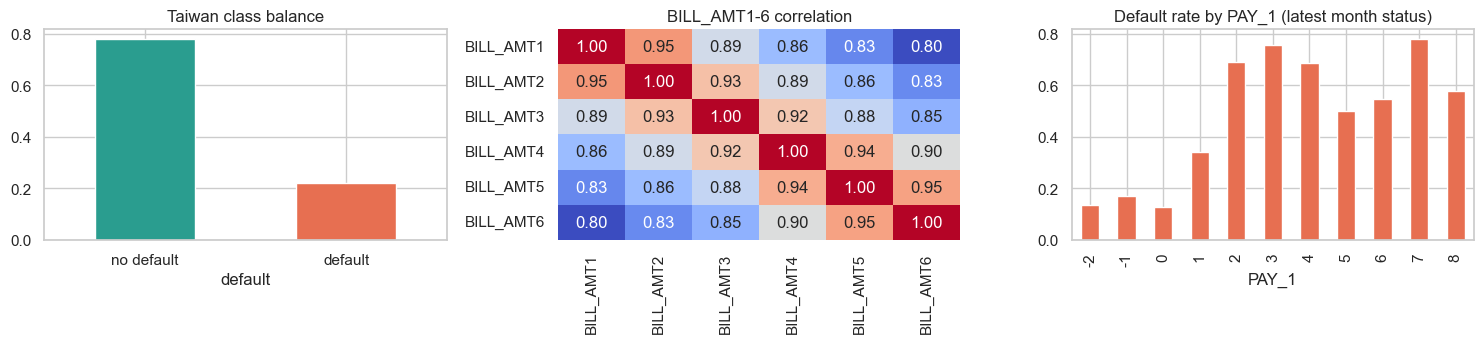

Skew LIMIT_BAL raw vs log: 0.99 -> -0.51


In [7]:
tw_dq = pd.DataFrame(tdq, columns=["issue", "rows_affected", "action"])
display(tw_dq)
display(tw[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_1"]].describe().round(1).T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
tw["default"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Taiwan class balance"); ax[0].set_xticklabels(["no default", "default"], rotation=0)
sns.heatmap(tw[BILL].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], cbar=False)
ax[1].set_title("BILL_AMT1-6 correlation")
tw.groupby("PAY_1")["default"].mean().plot.bar(ax=ax[2], color="#e76f51"); ax[2].set_title("Default rate by PAY_1 (latest month status)")
plt.tight_layout(); plt.show()
print("Skew LIMIT_BAL raw vs log:", round(tw["LIMIT_BAL"].skew(), 2), "->", round(tw["log_LIMIT_BAL"].skew(), 2))

## Result Interpretation — Taiwan data-quality summary
### What did we actually get?
* **Issues table:** 35 duplicates, 345 education recodes, 54 marriage recodes, 6,531 rows with a −2 code, 1,930 rows with a negative bill, ages 21–79, and no leakage columns.
* **Bill correlations:** `BILL_AMT1–6` are strongly correlated. Neighbouring months are near 0.95, and month 1 vs month 6 is about 0.80.
* **Default rate by `PAY_1`:** about 13–17% for codes −2, −1 and 0 (no balance, paid duly, revolving). It rises to **34%** for 1 month late and **69%** for 2 months late, and stays at 50–78% for the rare longer delays.
* **Skew of `LIMIT_BAL`:** 0.99 raw, −0.51 after log.
### What does it mean?
* **Multicollinearity is high here, unlike Lending Club.** Regularization (Week 2) and PCR/PLS (Week 3) should matter much more on this dataset.
* **`PAY_1` is the dominant risk signal.** Any later model that does not rank it highly deserves suspicion.
* **About 22% default,** a similar imbalance to Lending Club, so the same metrics apply.
### What should we do next?
Move to the modeling for this week (Part B).

## Part B — Regularized regression
### Key concepts (read before the code)
* **OLS** minimizes squared error only. With many correlated features it **overfits**: coefficients become large and unstable.
* **Ridge (L2)** minimizes `squared error + α·Σβ²`. It shrinks all coefficients toward 0 but never exactly to 0. It works well when many features each carry a little signal, or when features are correlated.
* **Lasso (L1)** minimizes `squared error + α·Σ|β|`. It can set coefficients **exactly to 0**, so it also selects features.
* **Elastic Net** mixes both: `α·[l1_ratio·Σ|β| + (1−l1_ratio)/2·Σβ²]`. It is useful when correlated features come in groups, where lasso tends to pick one at random.
* **α (lambda)** is the strength of the penalty. α → 0 gives back OLS; a very large α shrinks every coefficient to 0. We choose α by **5-fold cross-validation**: fit on 4/5 of the training data, score on the remaining 1/5, rotate, and average.
* **Scaling is mandatory.** The penalty treats every coefficient equally, so features must be on the same scale (`StandardScaler`) or large-unit features would be penalized unfairly.

## Cell 8 — Build the expanded feature matrices (degree-2 polynomial + one-hot)
### Why are we doing this?
Regularization only matters when there are many features relative to the signal. We expand each dataset with
`PolynomialFeatures(degree=2)`, which adds every square and pairwise product of the numeric features, plus one-hot categoricals.
### How does it work?
1. Split 80/20 with seed 42 (Lending Club: 25,000-loan sample, as in Week 1).
2. Inside a `ColumnTransformer`, numeric columns go through `StandardScaler → PolynomialFeatures(2) → StandardScaler`. The first scaling keeps the squares from blowing up; the second puts every expanded term on the same scale for the penalty.
3. Categoricals are one-hot encoded with the first level dropped.
4. Everything is fit on the **training data only**, then applied to the test set, so no test information leaks in.
**Lending Club excludes `grade`.** Week 1 showed grade alone explains about 91% of `int_rate`; here we ask what the raw borrower features can do.
### What should we examine after execution?
The number of expanded features per dataset and the number of training rows per feature.

In [8]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV, lasso_path
from sklearn.metrics import mean_squared_error, r2_score
FIG = "../../../week_10092026_w7/DX799O1/figures"  # report figures folder (relative to this notebook)
os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "log_annual_inc", "dti", "revol_util", "inq_last_6mths", "open_acc", "total_acc",
          "mort_acc", "delinq_2yrs", "pub_rec", "log_revol_bal", "pub_rec_bankruptcies"]
LC_CAT = ["term", "home_ownership", "purpose", "verification_status"]
TW_NUM = ["AGE", "PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] + [f"log_BILL_AMT{i}" for i in range(1, 7)] + [f"log_PAY_AMT{i}" for i in range(1, 7)]
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

def make_prep(num, cat):
    return ColumnTransformer([
        ("num", make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler()), num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat)])

data = {}
lc_s = lc.sample(n=25_000, random_state=SEED)
a, b = train_test_split(lc_s, test_size=0.2, random_state=SEED)
data["Lending Club"] = (a[LC_NUM + LC_CAT], a["int_rate"], b[LC_NUM + LC_CAT], b["int_rate"], LC_NUM, LC_CAT)
a, b = train_test_split(tw, test_size=0.2, random_state=SEED, stratify=tw["default"])
data["Taiwan"] = (a[TW_NUM + TW_CAT], a["log_LIMIT_BAL"], b[TW_NUM + TW_CAT], b["log_LIMIT_BAL"], TW_NUM, TW_CAT)

mats = {}
for name, (Xtr, ytr, Xte, yte, num, cat) in data.items():
    prep = make_prep(num, cat).fit(Xtr)
    Ztr, Zte = prep.transform(Xtr), prep.transform(Xte)
    mats[name] = (Ztr, ytr.values, Zte, yte.values, prep.get_feature_names_out())
    print(f"{name}: raw numeric {len(num)} + categorical {len(cat)} -> expanded features {Ztr.shape[1]} | "
          f"train rows {Ztr.shape[0]:,} ({Ztr.shape[0]/Ztr.shape[1]:.0f} rows per feature) | target SD {ytr.std():.3f}")

Lending Club: raw numeric 12 + categorical 4 -> expanded features 108 | train rows 20,000 (185 rows per feature) | target SD 4.762
Taiwan: raw numeric 19 + categorical 3 -> expanded features 215 | train rows 23,972 (111 rows per feature) | target SD 0.943


## Result Interpretation — Expanded features
### What did we actually get?
* **Lending Club:** 12 numeric + 4 categorical inputs become **108 features**, with 20,000 training rows (**185 rows per feature**). Target SD is 4.762.
* **Taiwan:** 19 numeric + 3 categorical inputs become **215 features**, with 23,972 training rows (**111 rows per feature**). Target SD is 0.943 log units.
### What does it mean?
* **Sample size:** 100+ rows per feature is a comfortable ratio for OLS, so we should not expect huge gains from regularization on the full training set. The final cell tests smaller samples.
* **RMSE benchmarks:** the target SDs (4.76 and 0.94) are what "predict the mean" would score.

## Cell 9 — Cross-validated error across α for Ridge and Lasso (the bias–variance curve)
### Why are we doing this?
This is the core tuning picture. For each α on a log grid from 10⁻⁴ to 10³ we compute the 5-fold CV RMSE (mean ± SD).
* **Small α:** behaves like OLS (low bias, high variance).
* **Large α:** everything shrinks toward 0 (high bias, underfitting).
* The minimum of the curve is the best trade-off. We also mark the **1-SE rule**: the largest α whose CV error is within one standard error of the minimum. It gives a simpler model that is statistically just as good.
### Alternatives
`RidgeCV`/`LassoCV` find the best α automatically (used in the next cell). Here we loop explicitly so the full curve can be plotted.
### What should we examine after execution?
The α that minimizes CV RMSE, how flat the curve is near the minimum, and where it rises steeply (too much shrinkage).

Lending Club Ridge: best alpha=0.4642 CV RMSE=3.6016 (+-0.0045) | 1-SE alpha=100 | CV RMSE at smallest alpha=3.6016, at largest=3.6581
Lending Club Lasso: best alpha=0.0004642 CV RMSE=3.6014 (+-0.0045) | 1-SE alpha=0.01 | CV RMSE at smallest alpha=3.6015, at largest=4.7618
Taiwan       Ridge: best alpha=100 CV RMSE=0.7131 (+-0.0017) | 1-SE alpha=215.4 | CV RMSE at smallest alpha=0.7135, at largest=0.7183
Taiwan       Lasso: best alpha=0.0004642 CV RMSE=0.7125 (+-0.0016) | 1-SE alpha=0.001 | CV RMSE at smallest alpha=0.7132, at largest=0.9433


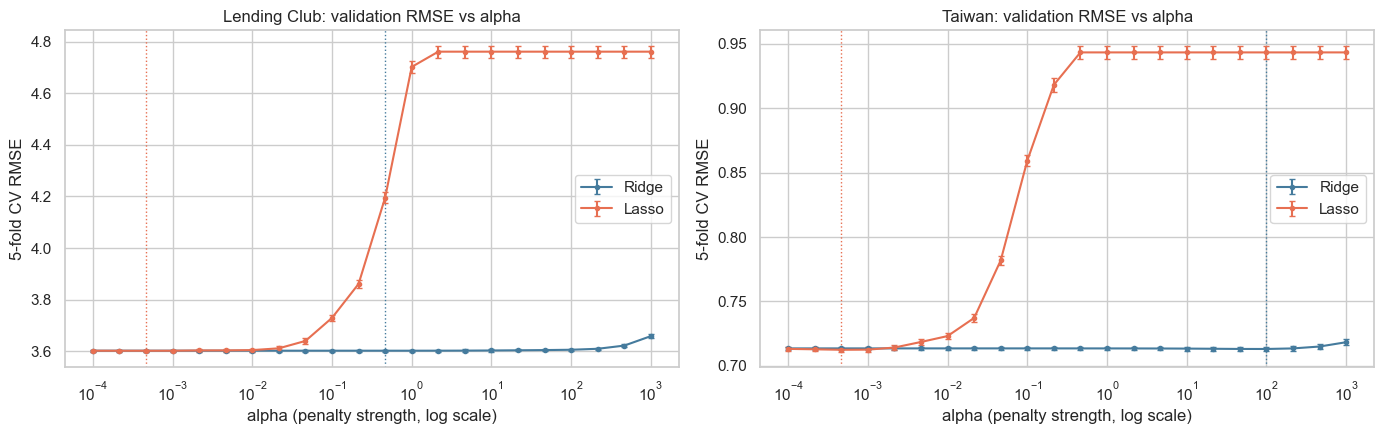

In [9]:
kf = KFold(5, shuffle=True, random_state=SEED)
alphas = np.logspace(-4, 3, 22)
curves = {}
for name, (Ztr, ytr, Zte, yte, feats) in mats.items():
    for mdl, est in [("Ridge", Ridge), ("Lasso", Lasso)]:
        res = []
        for a_ in alphas:
            s = np.sqrt(-cross_val_score(est(alpha=a_, max_iter=5000) if mdl == "Lasso" else est(alpha=a_), Ztr, ytr, cv=kf,
                                         scoring="neg_mean_squared_error"))
            res.append((a_, s.mean(), s.std() / np.sqrt(len(s))))
        curves[(name, mdl)] = pd.DataFrame(res, columns=["alpha", "cv_rmse", "se"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, mats):
    for mdl, col in [("Ridge", "#457b9d"), ("Lasso", "#e76f51")]:
        c = curves[(name, mdl)]
        ax.errorbar(c["alpha"], c["cv_rmse"], yerr=c["se"], label=mdl, color=col, marker="o", ms=3, capsize=2)
        best = c.loc[c["cv_rmse"].idxmin()]
        ax.axvline(best["alpha"], color=col, ls=":", lw=1)
        one_se = c[c["cv_rmse"] <= best["cv_rmse"] + best["se"]]["alpha"].max()
        print(f"{name:12s} {mdl}: best alpha={best['alpha']:.4g} CV RMSE={best['cv_rmse']:.4f} (+-{best['se']:.4f}) | 1-SE alpha={one_se:.4g} | "
              f"CV RMSE at smallest alpha={c['cv_rmse'].iloc[0]:.4f}, at largest={c['cv_rmse'].iloc[-1]:.4f}")
    ax.set_xscale("log"); ax.set_xlabel("alpha (penalty strength, log scale)"); ax.set_ylabel("5-fold CV RMSE")
    ax.set_title(f"{name}: validation RMSE vs alpha"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w2_alpha_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## Result Interpretation — CV RMSE vs α
### What did we actually get?
| Dataset | Model | Best α | CV RMSE (±SE) | 1-SE α | CV RMSE at the largest α |
|---|---|---|---|---|---|
| Lending Club | Ridge | 0.464 | 3.6016 (±0.0045) | 100 | 3.6581 |
| Lending Club | Lasso | 0.000464 | 3.6014 (±0.0045) | 0.01 | 4.7618 |
| Taiwan | Ridge | 100 | 0.7131 (±0.0017) | 215.4 | 0.7183 |
| Taiwan | Lasso | 0.000464 | 0.7125 (±0.0016) | 0.001 | 0.9433 |
### How should we read it?
* **Flat left side.** The curves are flat at small α, so CV error at the smallest α (≈ OLS) is within one SE of the best. On the full training sets, the penalty barely changes error.
* **Right side and the bias–variance trade-off.** Lasso's error rises to the target SD (4.76 and 0.94) at large α. Every coefficient has been shrunk to 0, leaving a model that predicts the mean (pure bias). Ridge rises much more slowly because it never removes features entirely.
* **The two penalties live on different scales.** Taiwan ridge picks α = 100 and lasso picks α ≈ 0.0005. Ridge penalizes squared coefficients and lasso absolute values, so their α values are not comparable.
* **1-SE rule.** Lasso α could rise to 0.01 (Lending Club) or 0.001 (Taiwan) with no significant loss. That gives a sparser model "for free".
### What does it mean?
* **Lending Club: little to gain.** The minimum is less than 0.1% below OLS, so regularization adds almost nothing.
* **Taiwan: a small but consistent gain.** Ridge prefers a much larger α (100), which is consistent with the strong bill collinearity from the data-quality step.

## Cell 10 — Fit OLS, RidgeCV, LassoCV and ElasticNetCV; compare on the held-out test set
### Why are we doing this?
CV picks α using only the training data; the **test set** is touched once, at the end, to estimate real-world error. OLS on
the same expanded features is the reference: if regularization helps, it should beat OLS on the test set.
### How does it work?
* `RidgeCV` uses an efficient leave-one-out-style search over α.
* `LassoCV`/`ElasticNetCV` run 5-fold CV along an α path.
* Elastic Net also searches `l1_ratio ∈ {0.1, 0.5, 0.9}`.
* We count **non-zero coefficients**, which shows how many features lasso and elastic net keep.
### What should we examine after execution?
Test RMSE and R² per method, the chosen α, and the number of non-zero coefficients compared with the total.

In [10]:
rows, fitted = [], {}
for name, (Ztr, ytr, Zte, yte, feats) in mats.items():
    models = {
        "OLS": LinearRegression(),
        "Ridge": RidgeCV(alphas=np.logspace(-3, 4, 60)),
        "Lasso": LassoCV(alphas=np.logspace(-4, 1, 60), cv=kf, max_iter=10000, n_jobs=-1),
        "ElasticNet": ElasticNetCV(alphas=np.logspace(-4, 1, 40), l1_ratio=[0.1, 0.5, 0.9], cv=kf, max_iter=10000, n_jobs=-1),
    }
    for mname, m in models.items():
        m.fit(Ztr, ytr); pred = m.predict(Zte); fitted[(name, mname)] = m
        rows.append({"dataset": name, "model": mname,
                     "alpha": getattr(m, "alpha_", np.nan), "l1_ratio": getattr(m, "l1_ratio_", np.nan),
                     "nonzero": int((np.abs(m.coef_) > 1e-10).sum()), "n_features": Ztr.shape[1],
                     "train_RMSE": np.sqrt(mean_squared_error(ytr, m.predict(Ztr))),
                     "test_RMSE": np.sqrt(mean_squared_error(yte, pred)), "test_R2": r2_score(yte, pred),
                     "max_abs_coef": np.abs(m.coef_).max()})
w2 = pd.DataFrame(rows)
display(w2.round(4))

,dataset,model,alpha,l1_ratio,nonzero,n_features,train_RMSE,test_RMSE,test_R2,max_abs_coef
0,Lending Club,OLS,NaN,NaN,108,108,3.5631,3.6037,0.4316,4.6584
1,Lending Club,Ridge,1.5973,NaN,108,108,3.5631,3.6033,0.4317,4.1918
2,Lending Club,Lasso,0.0003,NaN,107,108,3.5633,3.6031,0.4318,4.1928
3,Lending Club,ElasticNet,0.0003,0.9,108,108,3.5633,3.6030,0.4318,4.1920
4,Taiwan,OLS,NaN,NaN,215,215,0.7040,0.7046,0.4301,0.4539
5,Taiwan,Ridge,73.1824,NaN,215,215,0.7044,0.7036,0.4317,0.4384
6,Taiwan,Lasso,0.0007,NaN,153,215,0.7057,0.7033,0.4322,0.4483
7,Taiwan,ElasticNet,0.0008,0.9,153,215,0.7057,0.7033,0.4322,0.4478


## Result Interpretation — Test-set comparison
### What did we actually get?
| Dataset | Model | α | Non-zero / total | Test RMSE | Test R² |
|---|---|---|---|---|---|
| Lending Club | OLS | — | 108/108 | 3.6037 | 0.4316 |
| Lending Club | Ridge | 1.60 | 108/108 | 3.6033 | 0.4317 |
| Lending Club | Lasso | 0.0003 | 107/108 | 3.6031 | 0.4318 |
| Lending Club | ElasticNet (l1 0.9) | 0.0003 | 108/108 | **3.6030** | 0.4318 |
| Taiwan | OLS | — | 215/215 | 0.7046 | 0.4301 |
| Taiwan | Ridge | 73.2 | 215/215 | 0.7036 | 0.4317 |
| Taiwan | Lasso | 0.0007 | **153/215** | **0.7033** | **0.4322** |
| Taiwan | ElasticNet (l1 0.9) | 0.0008 | 153/215 | 0.7033 | 0.4322 |
### How should we interpret the numbers?
* **Overfitting check.** Train RMSE is about the same as test RMSE for every model (3.563 vs 3.603, and 0.704 vs 0.705). With 100+ rows per feature, OLS is not overfitting, so the penalty has little variance to remove.
* **Taiwan: same accuracy, fewer features.** Lasso drops **62 of 215 features (29%)** with no loss in accuracy and a 0.0013 RMSE improvement. The value is mainly in simplicity.
* **Elastic Net chose l1_ratio = 0.9.** That is almost pure lasso, which means the data prefers sparsity over ridge-style grouping.
* **Compared with Week 1:** expanding Lending Club's borrower features (without grade) lifts test R² from about 0.32 to **0.43**. The extra purpose, verification and home-ownership categories carry real price information.
### What can we NOT conclude?
That regularization is useless. It means **this sample size is large enough** that OLS is already stable. The last cell tests the small-sample case directly.

## Cell 11 — Lasso coefficient path and the features that survive
### Why are we doing this?
The **coefficient path** shows every coefficient as α decreases from "everything zero" to "almost OLS". Features that enter
early (at large α) carry the strongest independent signal. This is lasso's built-in feature selection, and it is easier to explain to a business audience than 200 small ridge coefficients.
### What should we examine after execution?
Which features enter first, how many survive at the CV-chosen α, and whether correlated features (e.g. the six bill months) are kept together or one at a time.

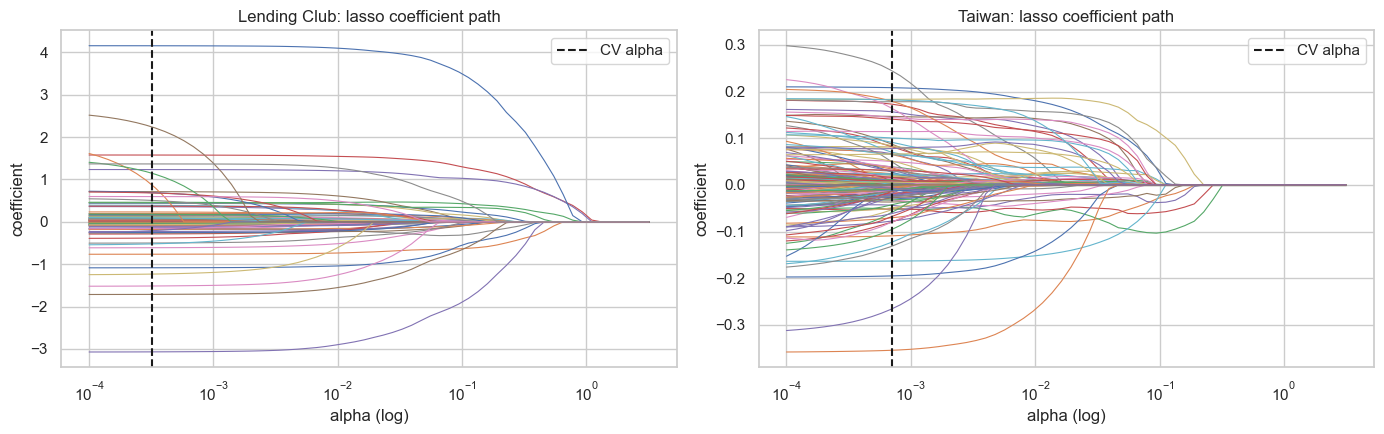


Lending Club: lasso keeps 107 of 108 features. Top 10 by |coef| (standardized units):
cat__term_ 60 months                 4.1928
cat__purpose_wedding                 3.9530
cat__purpose_renewable_energy        2.8129
cat__purpose_small_business          2.3772
cat__purpose_moving                  2.3630
cat__purpose_house                   2.1931
cat__purpose_other                   1.9167
num__revol_util                      1.5691
cat__verification_status_Verified    1.4363
cat__purpose_vacation                1.3532

Taiwan: lasso keeps 153 of 215 features. Top 10 by |coef| (standardized units):
cat__EDUCATION_3           -0.4483
cat__MARRIAGE_3            -0.3140
cat__EDUCATION_2           -0.2877
num__log_BILL_AMT1          0.2446
cat__EDUCATION_4           -0.1834
num__AGE                    0.1829
num__log_PAY_AMT6           0.1828
num__PAY_2 log_BILL_AMT1    0.1801
num__log_PAY_AMT5           0.1757
num__log_PAY_AMT1           0.1638


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, mats):
    Ztr, ytr, _, _, feats = mats[name]
    alphas_p, coefs, _ = lasso_path(Ztr, ytr - ytr.mean(), alphas=np.logspace(-4, 0.5, 60), max_iter=10000)
    ax.plot(alphas_p, coefs.T, lw=0.8)
    ax.axvline(fitted[(name, "Lasso")].alpha_, color="k", ls="--", label="CV alpha")
    ax.set_xscale("log"); ax.set_xlabel("alpha (log)"); ax.set_ylabel("coefficient"); ax.set_title(f"{name}: lasso coefficient path"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w2_lasso_path.png", dpi=150, bbox_inches="tight"); plt.show()
for name in mats:
    feats = mats[name][4]; m = fitted[(name, "Lasso")]
    top = pd.Series(m.coef_, index=feats); top = top[top.abs() > 0].sort_values(key=np.abs, ascending=False)
    print(f"\n{name}: lasso keeps {len(top)} of {len(feats)} features. Top 10 by |coef| (standardized units):")
    print(top.head(10).round(4).to_string())

## Result Interpretation — Lasso paths and surviving features
### What did we actually get?
**Plots:** at large α all paths sit at 0. As α falls, a handful of coefficients leave zero first, and most stay small until α ≈ 10⁻³. The CV-chosen α (dashed line) sits in the region where most features are active.

**Lending Club** (107 of 108 kept). The largest standardized coefficients are:
* `term_60 months` +4.19
* purposes: wedding +3.95, renewable energy +2.81, small business +2.38, moving +2.36, house +2.19, other +1.92
* `revol_util` +1.57
* `verification_status_Verified` +1.44

**Taiwan** (153 of 215 kept). The largest are:
* `EDUCATION_3` (high school) −0.45, `MARRIAGE_3` (other) −0.31, `EDUCATION_2` (university) −0.29
* `log_BILL_AMT1` +0.24, `AGE` +0.18
* recent payment amounts (+0.16 to +0.18)
* the interaction `PAY_2 × log_BILL_AMT1` +0.18
### What does it mean?
* **Lending Club:** the rate is set mostly by loan structure (60-month term) and loan purpose. Those are the lender's risk-class rules, which grade summarizes.
* **Taiwan:** the bank's limit decision follows education and marital status, the most recent bill, and payment amounts. Lasso drops many redundant cross-products of the six bill and payment months.
* **Lasso keeps 107 of 108 Lending Club features.** In that dataset each feature adds a little independent signal, which matches Week 3's finding that all 12 predictors survive stepwise selection.

## Cell 12 — Ridge vs Lasso coefficient shrinkage on the most collinear block (Taiwan bills)
### Why are we doing this?
To see *how* the penalties treat correlated predictors differently. We compare the linear `log_BILL_AMT1..6` coefficients under OLS, ridge and lasso.
### What should we examine after execution?
Whether OLS gives large alternating-sign coefficients (the classic multicollinearity symptom), whether ridge spreads the weight smoothly, and whether lasso keeps only a few.

In [12]:
Ztr, ytr, _, _, feats = mats["Taiwan"]
bill = [f"num__log_BILL_AMT{i}" for i in range(1, 7)]
idx = [list(feats).index(b) for b in bill]
cmp = pd.DataFrame({m: fitted[("Taiwan", m)].coef_[idx] for m in ["OLS", "Ridge", "Lasso", "ElasticNet"]}, index=[b.replace("num__", "") for b in bill])
display(cmp.round(4))

,OLS,Ridge,Lasso,ElasticNet
log_BILL_AMT1,0.3080,0.2649,0.2446,0.2430
log_BILL_AMT2,-0.0881,-0.0538,-0.0456,-0.0445
log_BILL_AMT3,-0.0144,-0.0095,-0.0059,-0.0055
log_BILL_AMT4,0.0202,0.0103,-0.0000,-0.0000
log_BILL_AMT5,-0.0528,-0.0395,-0.0197,-0.0193
log_BILL_AMT6,-0.0448,-0.0399,-0.0301,-0.0300


## Result Interpretation — How the penalties treat the collinear bill block
### What did we actually get?
* **OLS:** `BILL_AMT1` +0.308, then alternating signs (−0.088, −0.014, +0.020, −0.053, −0.045).
* **Ridge:** the same pattern, shrunk (+0.265, −0.054, …).
* **Lasso:** `BILL_AMT1` +0.245, with **`BILL_AMT4` set exactly to 0** and the others shrunk further.
### What does it mean?
* **The sign flips are a multicollinearity symptom.** The bills are correlated at about 0.8–0.95, so OLS assigns offsetting positive and negative weights that largely cancel. Ridge pulls them all toward 0 (more stable); lasso removes one and keeps the most recent month as the main carrier of the signal.
* **Business reading:** the latest statement balance is what the limit is associated with. Older months add little once it is known.

## Cell 13 — When does regularization pay off? Test RMSE vs training-set size
### Why are we doing this?
On the full training sets there are 111–185 rows per feature, so OLS is already stable. Regularization is designed for the
opposite case: few rows per feature. We refit OLS, RidgeCV and LassoCV on random training subsets of 300 to 20,000 rows
(same expanded features, same test set) to find the point where the penalty stops mattering.
### What should we examine after execution?
The gap between OLS and ridge/lasso test RMSE at small n, and the n at which the lines meet.

model                  Lasso      OLS   Ridge
dataset      n_train                         
Lending Club 300      3.9515  34.4624  4.1362
             600      3.9162   4.0356  4.0512
             1000     3.7691   3.8986  3.8294
             2000     3.7041   3.7218  3.7159
             5000     3.6552   3.6517  3.6538
             20000    3.6029   3.6037  3.6033
Taiwan       300      0.7819  10.5588  0.8049
             600      0.7576   1.6967  0.7807
             1000     0.7413   1.0582  0.7523
             2000     0.7289   0.8027  0.7409
             5000     0.7130   0.7294  0.7162
             20000    0.7040   0.7060  0.7046

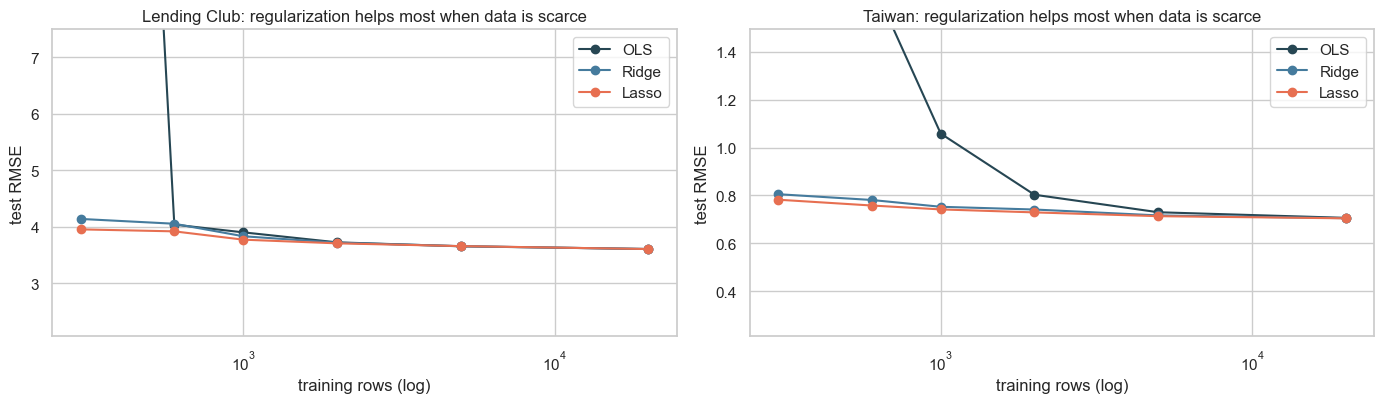

In [13]:
rng = np.random.RandomState(SEED)
sizes = [300, 600, 1000, 2000, 5000, 20000]
lc_rows = []
for name, (Ztr, ytr, Zte, yte, feats) in mats.items():
    for n_ in sizes:
        if n_ > len(ytr): continue
        idx = rng.choice(len(ytr), n_, replace=False)
        for mname, m in [("OLS", LinearRegression()), ("Ridge", RidgeCV(alphas=np.logspace(-2, 5, 50))),
                         ("Lasso", LassoCV(alphas=np.logspace(-4, 1, 40), cv=5, max_iter=10000, n_jobs=-1))]:
            m.fit(Ztr[idx], ytr[idx])
            lc_rows.append({"dataset": name, "n_train": n_, "model": mname,
                            "test_RMSE": np.sqrt(mean_squared_error(yte, m.predict(Zte)))})
lcurve = pd.DataFrame(lc_rows)
display(lcurve.pivot_table(index=["dataset", "n_train"], columns="model", values="test_RMSE").round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, name in zip(axes, mats):
    for mname, col in [("OLS", "#264653"), ("Ridge", "#457b9d"), ("Lasso", "#e76f51")]:
        d_ = lcurve[(lcurve.dataset == name) & (lcurve.model == mname)]
        ax.plot(d_["n_train"], d_["test_RMSE"], marker="o", label=mname, color=col)
    ax.set_xscale("log"); ax.set_xlabel("training rows (log)"); ax.set_ylabel("test RMSE")
    ax.set_title(f"{name}: regularization helps most when data is scarce")
    ax.set_ylim(top=min(ax.get_ylim()[1], lcurve[lcurve.dataset == name]["test_RMSE"].median() * 2)); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w2_learning_curve.png", dpi=150, bbox_inches="tight"); plt.show()

## Result Interpretation — Regularization vs training-set size
### What did we actually get?
| n train | LC OLS | LC Ridge | LC Lasso | TW OLS | TW Ridge | TW Lasso |
|---|---|---|---|---|---|---|
| 300 | **34.46** | 4.14 | **3.95** | **10.56** | 0.80 | **0.78** |
| 600 | 4.04 | 4.05 | 3.92 | 1.70 | 0.78 | 0.76 |
| 1,000 | 3.90 | 3.83 | 3.77 | 1.06 | 0.75 | 0.74 |
| 2,000 | 3.72 | 3.72 | 3.70 | 0.80 | 0.74 | 0.73 |
| 5,000 | 3.65 | 3.65 | 3.66 | 0.73 | 0.72 | 0.71 |
| 20,000 | 3.60 | 3.60 | 3.60 | 0.71 | 0.70 | 0.70 |
### What does it mean?
* **At 300 rows, OLS collapses.** With 108 or 215 features and only 300 rows, OLS memorizes noise. Its test RMSE is **34.5** for Lending Club (7× the target SD) and **10.6** for Taiwan (11× the SD). Ridge and lasso stay near 4.0 and 0.8.
* **This is the clearest evidence of variance reduction by regularization in the whole project.**
* **The gap closes by about 2,000 rows (Lending Club) or 5,000–20,000 rows (Taiwan).** Taiwan needs more data because it has twice as many features and much stronger collinearity.
* **Lasso is the best or tied-best in every Taiwan row,** which is consistent with many redundant features.
### What can we conclude?
* **When the penalty matters:** regularization is insurance that matters when rows per feature are scarce. With our full samples, it changes accuracy very little but buys sparsity (lasso: 29% fewer Taiwan features).
* **What this means for the capstone:** if the final model is built on a small segment (one state, one loan purpose), regularization becomes essential.
### What should we do next?
Week 3 compares selection (forward/backward) and rotation (PCR/PLSR) as alternative ways to handle many correlated features.